In [1]:
import geopandas as gpd
import pandas as pd


old_data = gpd.read_parquet("../data/input_files/uk_foursquare_datefields_admin_categories.parquet")
new_data = gpd.read_parquet("../data/input_files/uk_foursquare_cc_admin.parquet")


#644034b95e434270126654b1 in new_data
new_data_test = new_data[new_data['fsq_place_id'] == '644034b95e434270126654b1']
#new data filter anything that has a date_closed (not null) or no fsq_category_id
old_data_test = old_data[old_data['fsq_place_id'] == '9514bc258bd145613838867b']


In [2]:
#drop any with no fsq_category_id
new_data = new_data[new_data['fsq_category_id'].notna()]

In [ ]:
#print what fraction of the new data has a date_refreshed before 2015,2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023

In [3]:
#count the number of unique  fsq_place_id in each dataset
old_unique = old_data['fsq_place_id'].nunique()
new_unique = new_data['fsq_place_id'].nunique()
print(f"Old data unique fsq_place_id count: {old_unique}")
print(f"New data unique fsq_place_id count: {new_unique}")

Old data unique fsq_place_id count: 3812934
New data unique fsq_place_id count: 3854044


In [48]:
#convert string to datetime
old_data['date_refreshed'] = gpd.pd.to_datetime(old_data['date_refreshed'])
new_data['date_refreshed'] = gpd.pd.to_datetime(new_data['date_refreshed'])
old_data['date_created'] = gpd.pd.to_datetime(old_data['date_created'])
new_data['date_created'] = gpd.pd.to_datetime(new_data['date_created'])
#get min date_refreshed
min_date = old_data['date_refreshed'].min()
min_date

Timestamp('2012-06-06 00:00:00')

In [63]:
#join the two dataframes on fsq_place_id and keep the date columns for both
old_data = old_data[['fsq_place_id', 'date_refreshed', 'date_created','date_closed', 'name', 'fsq_category_ids']]
new_data = new_data[['fsq_place_id', 'date_refreshed', 'date_created','date_closed', 'name', 'fsq_category_id']]

#join
new_rows = new_data.merge(old_data, on='fsq_place_id', how='left', suffixes=('_new', '_old'))

#put pairs of columns next to each other
new_rows = new_rows[['fsq_place_id', 'name_new', 'name_old',
                     'date_refreshed_new', 'date_refreshed_old',
                     'date_created_new', 'date_created_old',
                     'date_closed_new', 'date_closed_old',
                     'fsq_category_id', 'fsq_category_ids']]

In [64]:
new_rows

,fsq_place_id,name_new,name_old,date_refreshed_new,date_refreshed_old,date_created_new,date_created_old,date_closed_new,date_closed_old,fsq_category_id,fsq_category_ids
0,5f04919b0654035c8098aa53,Horsey Beach,Horsey Beach,2024-12-03,2024-02-07,2020-07-07,2020-07-07,None,None,4bf58dd8d48988d1e2941735,4bf58dd8d48988d1e2941735
1,4c15006af1e0b713a1eb34bc,The Beach Café,The Beach Café,2024-08-17,2024-10-09,2010-06-13,2010-06-13,None,None,4bf58dd8d48988d1c7941735,4bf58dd8d48988d1c7941735
2,4ba5f36ef964a520ec2a39e3,Dunes Cafe,Dunes Cafe,2020-10-30,2024-02-07,2010-03-21,2010-03-21,None,None,4bf58dd8d48988d16d941735,4bf58dd8d48988d16d941735
3,61177e4454ff0843f151c7b3,Norfolk’s Edge,Norfolk’s Edge,2023-10-26,2024-02-07,2021-08-14,2021-08-14,None,None,4bf58dd8d48988d16d941735,4bf58dd8d48988d16d941735
4,4c2495de905a0f471eee5f60,Winterton On Sea Beach,Winterton On Sea Beach,2025-05-13,2024-02-07,2010-06-25,2010-06-25,None,None,4bf58dd8d48988d1e2941735,4bf58dd8d48988d1e2941735
...,...,...,...,...,...,...,...,...,...,...,...
2557540,536e4933498e867152e25320,Baltasound,Baltasound,2024-06-05,2020-12-08,2014-05-10,2014-05-10,None,None,50aa9e094b90af0d42d5de0d,50aa9e094b90af0d42d5de0d
2557541,4c2e6910ed37a593da8b6503,Baltasound Hotel,Baltasound Hotel,2023-08-23,2024-10-08,2010-07-02,2010-07-02,None,None,4bf58dd8d48988d1fa931735,4bf58dd8d48988d1fa931735
2557542,53cc4519498e1bf3446d0a79,Baltasound Harbour,Baltasound Harbour,2024-06-05,2024-10-09,2014-07-20,2014-07-20,None,None,4bf58dd8d48988d1e0941735,4bf58dd8d48988d1e0941735
2557543,64c52392f1a212750977a074,Norwick Beach,NaN,2023-07-29,NaT,2023-07-29,NaT,None,NaN,4bf58dd8d48988d1e2941735,NaN


In [4]:

new_data = new_data[(new_data['date_closed'].isnull()) & (new_data['fsq_category_id'].notnull()) 
]
old_data = old_data[(old_data['date_closed'].isnull()) & (old_data['fsq_category_ids'].notnull())
]

In [50]:
#remove from old_data anything that has a date_created after the date_refreshed
old_data = old_data[old_data['date_refreshed'] > old_data['date_created']]

In [55]:
new_data['date_refreshed'].min()

Timestamp('2020-01-02 00:00:00')

/tmp/ipykernel_781807/1522228253.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  bins = pd.date_range(start='2018-01-01', end='2021-12-31', freq='M')


<Axes: >

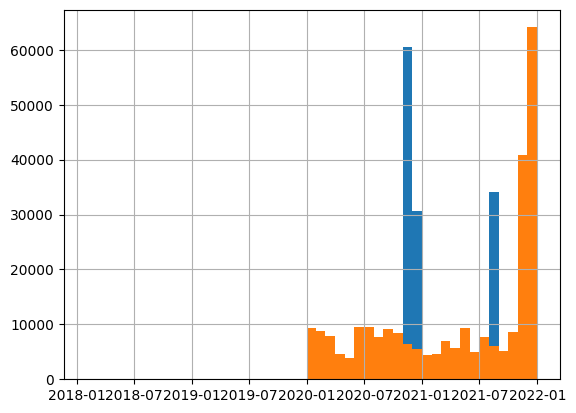

In [65]:
#bins between 2019 and 2021
bins = pd.date_range(start='2018-01-01', end='2021-12-31', freq='M')

old_data['date_refreshed'].hist(bins=bins)
new_data['date_refreshed'].hist(bins=bins)

In [5]:
#count the number of unique  fsq_place_id in each dataset
old_unique = old_data['fsq_place_id'].nunique()
new_unique = new_data['fsq_place_id'].nunique()
print(f"Old data unique fsq_place_id count: {old_unique}")
print(f"New data unique fsq_place_id count: {new_unique}")

Old data unique fsq_place_id count: 3512863
New data unique fsq_place_id count: 3531793


In [6]:
#count number of ids in old data that are not in new data
old_ids = set(old_data['fsq_place_id'])
new_ids = set(new_data['fsq_place_id'])
missing_ids = old_ids - new_ids
print(f"Number of fsq_place_id in old data not in new data: {len(missing_ids)}")
#get df of old rows
old_rows = old_data[old_data['fsq_place_id'].isin(missing_ids)]

Number of fsq_place_id in old data not in new data: 30857


In [7]:
#and vice versa
missing_ids_new = new_ids - old_ids
print(f"Number of fsq_place_id in new data not in old data: {len(missing_ids_new)}")

Number of fsq_place_id in new data not in old data: 49787


In [8]:
#get a df of the new rows
new_rows = new_data[new_data['fsq_place_id'].isin(missing_ids_new)]

In [9]:
#get ones with a date created since 2025
new_rows = new_rows[new_rows['date_created'] <= '2024-09-01']

In [10]:
new_rows

,fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,...,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm
95,5c5e3fc1bd3245eaa492f1e9,The Palace Casino,52.696107,1.700298,Beach Rd,Hemsby,Norfolk,NR29 4HS,England,Great Yarmouth,...,None,None,None,None,None,None,None,None,None,None
96,5c5e3fc1bd3245eaa492f1e9,The Palace Casino,52.696107,1.700298,Beach Rd,Hemsby,Norfolk,NR29 4HS,England,Great Yarmouth,...,None,None,None,None,None,None,None,None,None,None
486,71cdecfa863d4955c1b86843,J B Roofing & Property Maintenance Services,52.704490,1.586010,"Willow Cottage, 1a Tower Rd",Repps With Bastwick,Norfolk,NR29 5JW,England,Great Yarmouth,...,None,None,None,None,None,None,None,None,None,None
661,3fa39a7f43f742fe69c5e07e,Heathland Group Limited,52.688120,1.620759,8 Thorpe Rd Unit 5,Rollesby,Norfolk,NR29 5DR,England,Great Yarmouth,...,None,None,None,None,None,None,None,None,None,None
662,c297c2f252fa41e7a760a80a,Heathland Aquatic Engineering,52.688120,1.620759,8 Thorpe Rd Unit 5,Rollesby,Norfolk,NR29 5DR,England,Great Yarmouth,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4641619,8afe328ea00747d213b5c7c1,Wholesale Custom Boxes,60.392900,-1.259600,60 Kingsway North PARK Ave,Shetland,Shetland Islands,ZE2 1EJ,Scotland,Shetland,...,S01012411,North Mainland - 02,None,None,None,None,None,None,None,None
4641620,0979562626654a0a80a87548,Custom Shipping Boxes,60.392900,-1.259600,53 Kingsway North PARK Ave,Shetland,Shetland Islands,ZE2 1EX,Scotland,Shetland,...,S01012411,North Mainland - 02,None,None,None,None,None,None,None,None
4641680,5028ffa5e4b057b8a4a97569,Hermaness nature reserve,60.812773,-0.876560,None,None,Shetland,None,None,None,...,S01012414,North and East Isles - 02,None,None,None,None,None,None,None,None
4641791,bfda562b282b489fb163790b,Sandisons,60.757295,-0.860911,Skibhoul Stores,Brae,Shetland Islands,ZE2 9DP,Scotland,Shetland,...,None,None,None,None,None,None,None,None,None,None


In [19]:
new_rows["date_refreshed"].max(), new_rows["date_refreshed"].min()

('2025-06-08', '2009-09-02')

In [ ]:
#save to parquet
new_rows.to_parquet("../data/input_files/new_fsq_places_before_2025.parquet")


: 